# 04 — Tổng hợp thực nghiệm và đánh giá cuối cùng

## Mục tiêu
- Tổng hợp toàn bộ các thực nghiệm cross-validation: baseline, feature engineering,
  xử lý mất cân bằng (class weight, SMOTE) và tuning siêu tham số.
- Đo tác động riêng của từng thay đổi bằng so sánh cặp theo fold.
- Trình bày việc chọn ngưỡng quyết định trên xác suất out-of-fold.
- Báo cáo kết quả cuối cùng trên tập test và đối chiếu với cross-validation.
- Giải thích mô hình: đặc trưng nào ảnh hưởng nhiều nhất đến dự đoán churn.

Notebook chỉ **đọc** kết quả đã lưu trong `outputs/` và các pipeline trong
`outputs/models/tuned/`; không huấn luyện lại và không ghi file.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd()
PROJECT_ROOT = current_dir if (current_dir / "src").is_dir() else current_dir.parent
if not (PROJECT_ROOT / "outputs").is_dir():
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án hoặc notebooks/.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_train_test

OUTPUTS = PROJECT_ROOT / "outputs"
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

MODELS = ["logistic_regression", "decision_tree", "random_forest", "xgboost"]
MODEL_LABELS = {
    "logistic_regression": "Logistic Regression",
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
}
# Màu cố định theo mô hình (thứ tự categorical đã kiểm tra an toàn mù màu).
MODEL_COLORS = {
    "logistic_regression": "#2a78d6",
    "decision_tree": "#eb6834",
    "random_forest": "#1baf7a",
    "xgboost": "#eda100",
}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3de"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

## 1. Các lần chạy được tổng hợp

Mỗi cấu hình lấy **lần chạy mới nhất** (có đủ chỉ số PR-AUC). Tất cả dùng chung
5 fold (`StratifiedKFold`, `random_state=42`), nên có thể so sánh cặp theo từng fold.

In [2]:
RUNS = {
    "Baseline": "experiments/baseline_20261102_160548_478937",
    "FE": "experiments/feature_engineering_20261120_150939_370901",
    "Class weight": "experiments/baseline_class_weight_20261102_160607_528828",
    "SMOTE": "experiments/baseline_smote_20261102_160641_047219",
    "FE + class weight": "experiments/feature_engineering_class_weight_20261120_150849_054524",
    "FE + SMOTE": "experiments/feature_engineering_smote_20261120_150908_468160",
    "Tuned (class weight)": "tuning/tuned_class_weight_20261120_152344_517259",
}

folds, configs = [], {}
for name, rel in RUNS.items():
    run_dir = OUTPUTS / rel
    df = pd.read_csv(run_dir / "cv_results.csv")
    df["experiment"] = name
    folds.append(df)
    configs[name] = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))

folds = pd.concat(folds, ignore_index=True)

# Kiểm tra: mọi run cùng fold, đủ 4 mô hình x 5 fold.
assert {c["random_state"] for c in configs.values()} == {42}
assert {c["n_splits"] for c in configs.values()} == {5}
assert folds.groupby(["experiment", "model"]).size().eq(5).all()

display(pd.DataFrame({
    "experiment": list(configs),
    "feature_engineering": [c["feature_engineering"] for c in configs.values()],
    "imbalance": [c["imbalance"] for c in configs.values()],
    "run": [Path(r).name for r in RUNS.values()],
}))

,experiment,feature_engineering,imbalance,run
0,Baseline,False,none,baseline_20261102_160548_478937
1,FE,True,none,feature_engineering_20261120_150939_370901
2,Class weight,False,class_weight,baseline_class_weight_20261102_160607_528828
3,SMOTE,False,smote,baseline_smote_20261102_160641_047219
4,FE + class weight,True,class_weight,feature_engineering_class_weight_20261120_1508...
5,FE + SMOTE,True,smote,feature_engineering_smote_20261120_150908_468160
6,Tuned (class weight),False,class_weight,tuned_class_weight_20261120_152344_517259


## 2. Bảng tổng hợp cross-validation

Giá trị là trung bình ± độ lệch chuẩn trên 5 fold validation.

In [3]:
METRICS = ["precision", "recall", "f1", "roc_auc", "pr_auc"]

summary = (
    folds.groupby(["experiment", "model"], sort=False)
    [[f"val_{m}" for m in METRICS] + ["train_f1"]]
    .agg(["mean", "std"])
)

table = pd.DataFrame(index=summary.index)
for m in METRICS:
    table[m] = [
        f"{a:.3f} ± {b:.3f}"
        for a, b in zip(summary[(f"val_{m}", "mean")], summary[(f"val_{m}", "std")])
    ]
table["train_f1"] = summary[("train_f1", "mean")].map("{:.3f}".format)
table = table.rename(index=MODEL_LABELS, level="model")
display(table)

precision         recall  \
experiment           model                                               
Baseline             Logistic Regression  0.652 ± 0.029  0.543 ± 0.046   
                     Decision Tree        0.489 ± 0.011  0.496 ± 0.014   
                     Random Forest        0.628 ± 0.026  0.480 ± 0.021   
                     XGBoost              0.650 ± 0.025  0.520 ± 0.023   
FE                   Logistic Regression  0.667 ± 0.024  0.537 ± 0.038   
                     Decision Tree        0.493 ± 0.015  0.498 ± 0.019   
                     Random Forest        0.631 ± 0.046  0.464 ± 0.019   
                     XGBoost              0.645 ± 0.042  0.505 ± 0.029   
Class weight         Logistic Regression  0.517 ± 0.021  0.801 ± 0.042   
                     Decision Tree        0.512 ± 0.027  0.496 ± 0.026   
                     Random Forest        0.563 ± 0.019  0.637 ± 0.031   
                     XGBoost              0.545 ± 0.022  0.747 ± 0.037   
SMOTE                Logistic Regression  0.526 ± 0.020  0.789 ± 0.045   
                     Decision Tree        0.479 ± 0.013  0.495 ± 0.035   
                     Random Forest        0.608 ± 0.031  0.496 ± 0.035   
                     XGBoost              0.636 ± 0.016  0.565 ± 0.022   
FE + class weight    Logistic Regression  0.522 ± 0.015  0.792 ± 0.041   
                     Decision Tree        0.496 ± 0.023  0.494 ± 0.024   
                     Random Forest        0.562 ± 0.027  0.628 ± 0.033   
                     XGBoost              0.549 ± 0.011  0.730 ± 0.031   
FE + SMOTE           Logistic Regression  0.528 ± 0.015  0.784 ± 0.034   
                     Decision Tree        0.480 ± 0.018  0.504 ± 0.043   
                     Random Forest        0.617 ± 0.039  0.506 ± 0.024   
                     XGBoost              0.624 ± 0.022  0.558 ± 0.034   
Tuned (class weight) Logistic Regression  0.517 ± 0.021  0.801 ± 0.042   
                     Decision Tree        0.508 ± 0.026  0.799 ± 0.028   
                     Random Forest        0.531 ± 0.020  0.776 ± 0.032   
                     XGBoost              0.520 ± 0.019  0.806 ± 0.033   

                                                     f1        roc_auc  \
experiment           model                                               
Baseline             Logistic Regression  0.592 ± 0.033  0.846 ± 0.014   
                     Decision Tree        0.492 ± 0.008  0.654 ± 0.006   
                     Random Forest        0.544 ± 0.019  0.820 ± 0.011   
                     XGBoost              0.578 ± 0.018  0.841 ± 0.008   
FE                   Logistic Regression  0.595 ± 0.027  0.846 ± 0.013   
                     Decision Tree        0.495 ± 0.016  0.657 ± 0.011   
                     Random Forest        0.534 ± 0.029  0.823 ± 0.013   
                     XGBoost              0.566 ± 0.025  0.838 ± 0.009   
Class weight         Logistic Regression  0.628 ± 0.026  0.846 ± 0.014   
                     Decision Tree        0.504 ± 0.021  0.663 ± 0.014   
                     Random Forest        0.598 ± 0.024  0.822 ± 0.015   
                     XGBoost              0.630 ± 0.026  0.839 ± 0.010   
SMOTE                Logistic Regression  0.631 ± 0.026  0.845 ± 0.015   
                     Decision Tree        0.487 ± 0.018  0.651 ± 0.013   
                     Random Forest        0.546 ± 0.030  0.816 ± 0.015   
                     XGBoost              0.598 ± 0.012  0.841 ± 0.008   
FE + class weight    Logistic Regression  0.629 ± 0.021  0.845 ± 0.013   
                     Decision Tree        0.495 ± 0.022  0.657 ± 0.015   
                     Random Forest        0.593 ± 0.030  0.825 ± 0.011   
                     XGBoost              0.626 ± 0.017  0.839 ± 0.008   
FE + SMOTE           Logistic Regression  0.631 ± 0.020  0.844 ± 0.014   
                     Decision Tree        0.491 ± 0.026  0.654 ± 0.017   
                     Random Forest        0.556 ±

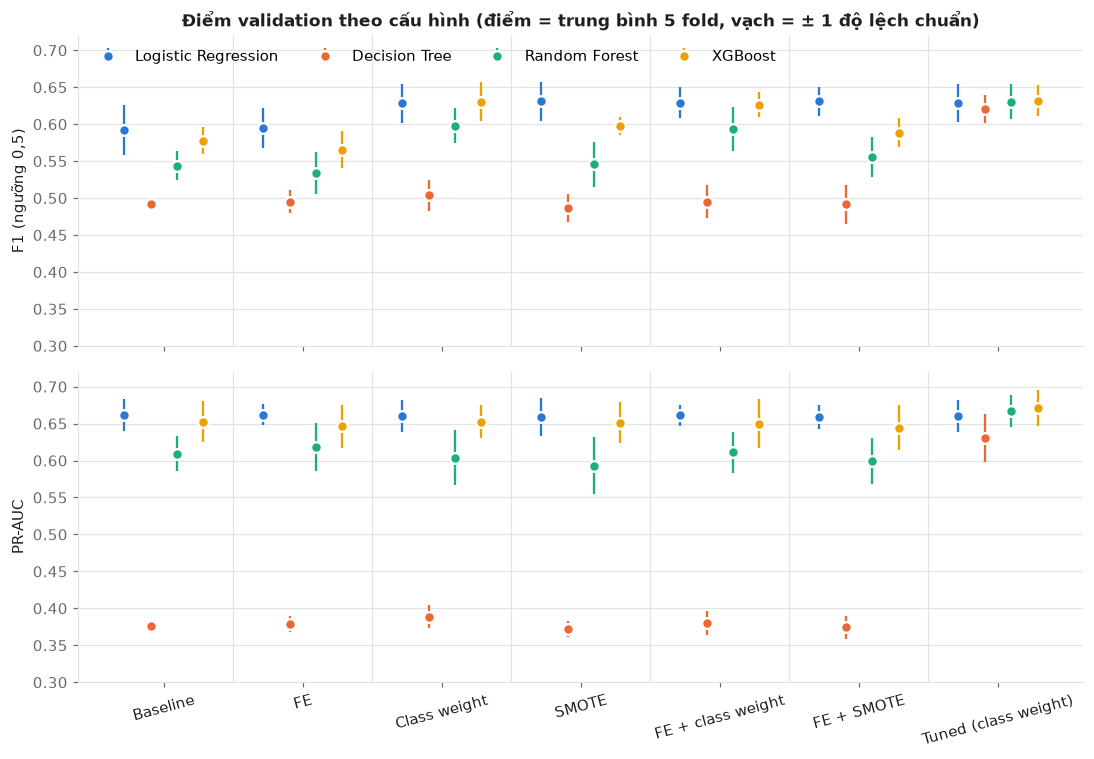

In [4]:
order = list(RUNS)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
width = 0.19

for ax, metric, label in zip(axes, ["f1", "pr_auc"], ["F1 (ngưỡng 0,5)", "PR-AUC"]):
    for i, model in enumerate(MODELS):
        s = summary.xs(model, level="model").reindex(order)
        x = np.arange(len(order)) + (i - 1.5) * width
        # Dùng điểm + vạch sai số thay vì cột, vì trục y không bắt đầu từ 0.
        ax.errorbar(
            x, s[(f"val_{metric}", "mean")], yerr=s[(f"val_{metric}", "std")],
            fmt="o", markersize=7, color=MODEL_COLORS[model],
            markeredgecolor="white", markeredgewidth=1.5,
            ecolor=MODEL_COLORS[model], elinewidth=1.5, capsize=0,
            label=MODEL_LABELS[model],
        )
    ax.set_ylabel(label)
    ax.set_ylim(0.3, 0.72)
    ax.grid(axis="x", visible=False)

for ax in axes:
    for k in range(len(order) - 1):
        ax.axvline(k + 0.5, color=GRID, linewidth=0.8)
axes[0].set_title("Điểm validation theo cấu hình (điểm = trung bình 5 fold, vạch = ± 1 độ lệch chuẩn)")
axes[0].legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.0))
axes[1].set_xticks(np.arange(len(order)), order, rotation=15, color=INK)
fig.tight_layout()
plt.show()

## 3. Tác động của từng thay đổi (so sánh cặp theo fold)

Vì mọi run dùng cùng 5 fold, ta tính chênh lệch **trên từng fold** rồi lấy trung bình.
`wins` là số fold mà cấu hình mới tốt hơn. Một thay đổi được coi là có ích rõ ràng
khi chênh lệch trung bình lớn hơn độ dao động giữa các fold và thắng ở hầu hết các fold.

In [5]:
def paired(base, new, metric):
    a = folds[folds.experiment == base].set_index(["model", "fold"])[f"val_{metric}"]
    b = folds[folds.experiment == new].set_index(["model", "fold"])[f"val_{metric}"]
    diff = (b - a).groupby("model")
    return pd.DataFrame({
        "diff_mean": diff.mean(),
        "diff_std": diff.std(),
        "wins": diff.apply(lambda d: f"{int((d > 0).sum())}/{len(d)}"),
    }).reindex(MODELS)

COMPARISONS = [
    ("Feature engineering", "Baseline", "FE"),
    ("Feature engineering (khi đã có class weight)", "Class weight", "FE + class weight"),
    ("Class weight", "Baseline", "Class weight"),
    ("SMOTE", "Baseline", "SMOTE"),
    ("Tuning", "Class weight", "Tuned (class weight)"),
]

rows = []
for label, base, new in COMPARISONS:
    for metric in ["f1", "recall", "pr_auc"]:
        r = paired(base, new, metric)
        for model, v in r.iterrows():
            rows.append({
                "thay đổi": label, "metric": metric, "model": MODEL_LABELS[model],
                "chênh lệch": f"{v.diff_mean:+.3f} ± {v.diff_std:.3f}", "wins": v.wins,
            })

effects = pd.DataFrame(rows).pivot_table(
    index=["thay đổi", "model"], columns="metric",
    values=["chênh lệch", "wins"], aggfunc="first", sort=False,
)
effects = effects.reindex(columns=["f1", "recall", "pr_auc"], level="metric")
display(effects)

chênh lệch  \
metric                                                                        f1   
thay đổi                                     model                                 
Feature engineering                          Logistic Regression  +0.002 ± 0.014   
                                             Decision Tree        +0.003 ± 0.017   
                                             Random Forest        -0.010 ± 0.028   
                                             XGBoost              -0.012 ± 0.011   
Feature engineering (khi đã có class weight) Logistic Regression  +0.001 ± 0.008   
                                             Decision Tree        -0.008 ± 0.014   
                                             Random Forest        -0.005 ± 0.012   
                                             XGBoost              -0.004 ± 0.019   
Class weight                                 Logistic Regression  +0.036 ± 0.021   
                                             Decision Tree        +0.012 ± 0.024   
                                             Random Forest        +0.054 ± 0.026   
                                             XGBoost              +0.053 ± 0.023   
SMOTE                                        Logistic Regression  +0.039 ± 0.018   
                                             Decision Tree        -0.006 ± 0.021   
                                             Random Forest        +0.002 ± 0.024   
                                             XGBoost              +0.020 ± 0.011   
Tuning                                       Logistic Regression  +0.000 ± 0.001   
                                             Decision Tree        +0.117 ± 0.014   
                                             Random Forest        +0.033 ± 0.020   
                                             XGBoost              +0.002 ± 0.007   

                                                                                  \
metric                                                                    recall   
thay đổi                                     model                                 
Feature engineering                          Logistic Regression  -0.006 ± 0.017   
                                             Decision Tree        +0.002 ± 0.025   
                                             Random Forest        -0.017 ± 0.028   
                                             XGBoost              -0.015 ± 0.009   
Feature engineering (khi đã có class weight) Logistic Regression  -0.009 ± 0.010   
                                             Decision Tree        -0.002 ± 0.011   
                                             Random Forest        -0.009 ± 0.009   
                                             XGBoost              -0.017 ± 0.022   
Class weight                                 Logistic Regression  +0.258 ± 0.023   
                                             Decision Tree        +0.001 ± 0.018   
                                             Random Forest        +0.157 ± 0.035   
                                             XGBoost              +0.227 ± 0.034   
SMOTE                                        Logistic Regression  +0.245 ± 0.020   
                                             Decision Tree        -0.001 ± 0.039   
                                             Random Forest        +0.015 ± 0.029   
                                             XGBoost              +0.044 ± 0.012   
Tuning                                       Logistic Regression  +0.000 ± 0.000   
                                             Decision Tree        +0.302 ± 0.035   
                                             Random Forest        +0.138 ± 0.020   
                                             XGBoost              +0.059 ± 0.014   

                                                                                  \
metric                                                                    pr_auc   
thay đổi                            

## 4. Overfitting: khoảng cách train – validation

So sánh F1 trên fold train và fold validation, trước (class weight, tham số mặc định)
và sau tuning.

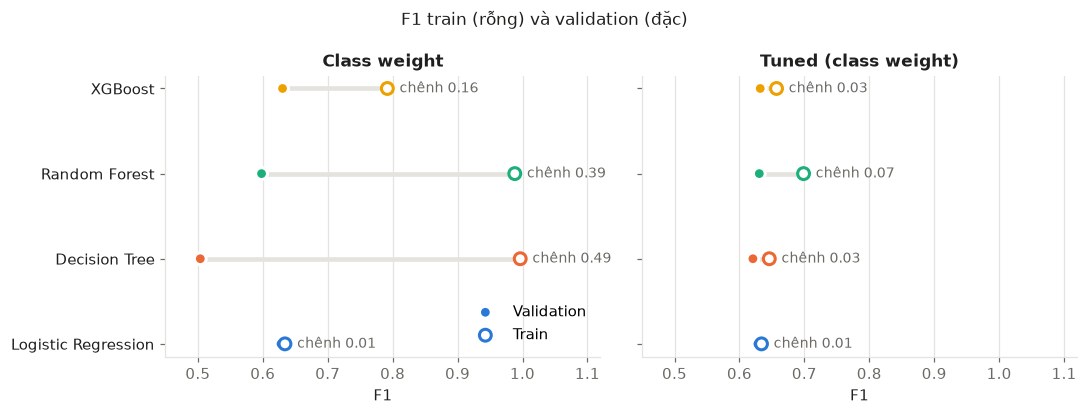

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)

for ax, exp in zip(axes, ["Class weight", "Tuned (class weight)"]):
    s = summary.xs(exp, level="experiment").reindex(MODELS)
    y = np.arange(len(MODELS))
    ax.hlines(y, s[("val_f1", "mean")], s[("train_f1", "mean")], color=GRID, linewidth=3)
    ax.scatter(s[("val_f1", "mean")], y, s=60, color=[MODEL_COLORS[m] for m in MODELS],
               edgecolor="white", linewidth=2, zorder=3, label="Validation")
    ax.scatter(s[("train_f1", "mean")], y, s=60, facecolor="white",
               edgecolor=[MODEL_COLORS[m] for m in MODELS], linewidth=2, zorder=3, label="Train")
    for yi, m in zip(y, MODELS):
        gap = s.loc[m, ("train_f1", "mean")] - s.loc[m, ("val_f1", "mean")]
        ax.annotate(f"chênh {gap:.2f}", (s.loc[m, ("train_f1", "mean")], yi),
                    xytext=(8, 0), textcoords="offset points", va="center", color=MUTED, fontsize=9)
    ax.set_yticks(y, [MODEL_LABELS[m] for m in MODELS], color=INK)
    ax.set_xlim(0.45, 1.12)
    ax.set_xlabel("F1")
    ax.set_title(exp)
    ax.grid(axis="y", visible=False)

axes[0].legend(loc="lower right")
fig.suptitle("F1 train (rỗng) và validation (đặc)", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

In [7]:
best_params = json.loads(
    (OUTPUTS / RUNS["Tuned (class weight)"] / "best_params.json").read_text(encoding="utf-8")
)
display(pd.DataFrame(
    [(MODEL_LABELS[m], k.replace("model__", ""), v) for m, p in best_params.items() for k, v in p.items()],
    columns=["model", "tham số", "giá trị tốt nhất"],
).set_index(["model", "tham số"]))

giá trị tốt nhất
model               tham số                          
Logistic Regression C                          0.9164
Decision Tree       criterion                 entropy
                    max_depth                      12
                    min_samples_leaf               51
Random Forest       max_depth                       8
                    max_features               0.5000
                    min_samples_leaf               11
                    n_estimators                  287
XGBoost             colsample_bytree           0.9633
                    learning_rate              0.0226
                    max_depth                       3
                    min_child_weight                5
                    n_estimators                  271
                    reg_lambda                 0.7863
                    subsample                  0.8212

## 5. Chọn ngưỡng quyết định

Ngưỡng được chọn trên **xác suất out-of-fold** của tập train (mỗi khách hàng được
dự đoán bởi mô hình không thấy họ lúc huấn luyện), nên tập test không được dùng.
Hai tiêu chí: tối đa F1 (beta = 1, ngưỡng chính) và tối đa F2 (beta = 2, ưu tiên recall).

In [8]:
TH_F1 = OUTPUTS / "thresholds/thresholds_20261120_160749_204990"
TH_F2 = OUTPUTS / "thresholds/thresholds_20261120_160508_291871"

th1 = json.loads((TH_F1 / "thresholds.json").read_text(encoding="utf-8"))
th2 = json.loads((TH_F2 / "thresholds.json").read_text(encoding="utf-8"))
assert th1["beta"] == 1.0 and th2["beta"] == 2.0

s1 = pd.read_csv(TH_F1 / "summary.csv").set_index("model")
display(pd.DataFrame({
    "ngưỡng F1": pd.Series(th1["thresholds"]),
    "ngưỡng F2": pd.Series(th2["thresholds"]),
    "F1 ở 0,5": s1["f1_at_0.5"],
    "F1 ở ngưỡng F1": s1["f1_at_best"],
    "fold thắng": s1["fold_wins"],
}).rename(index=MODEL_LABELS))

,ngưỡng F1,ngưỡng F2,"F1 ở 0,5",F1 ở ngưỡng F1,fold thắng
Logistic Regression,0.6000,0.3200,0.6285,0.6367,4/5
Decision Tree,0.6000,0.2600,0.6204,0.6283,3/5
Random Forest,0.6000,0.3400,0.6306,0.6388,4/5
XGBoost,0.5700,0.3700,0.6320,0.6390,3/5


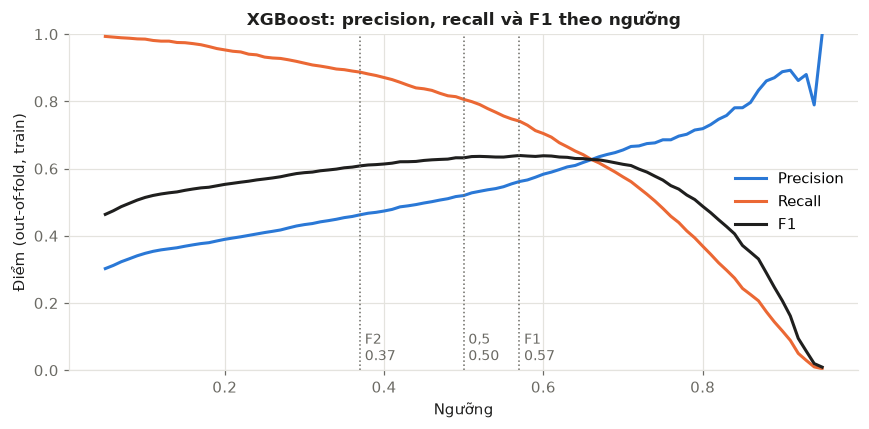

In [9]:
scores = pd.read_csv(TH_F1 / "xgboost_threshold_scores.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(scores.threshold, scores.precision, color="#2a78d6", linewidth=2, label="Precision")
ax.plot(scores.threshold, scores.recall, color="#eb6834", linewidth=2, label="Recall")
ax.plot(scores.threshold, scores.f1, color=INK, linewidth=2, label="F1")

for t, name in [(0.5, "0,5"), (th1["thresholds"]["xgboost"], "F1"), (th2["thresholds"]["xgboost"], "F2")]:
    ax.axvline(t, color=MUTED, linestyle=":", linewidth=1)
    ax.annotate(f"{name}\n{t:.2f}", (t, 0.03), xytext=(3, 0), textcoords="offset points",
                color=MUTED, fontsize=9)

ax.set_xlabel("Ngưỡng")
ax.set_ylabel("Điểm (out-of-fold, train)")
ax.set_ylim(0, 1)
ax.set_title("XGBoost: precision, recall và F1 theo ngưỡng")
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

## 6. Kết quả trên tập test

Tập test (1.409 khách hàng, 374 người rời) chỉ được dùng **một lần**, sau khi mọi lựa chọn
(cấu hình, tham số, ngưỡng, mô hình chính) đã được chốt bằng cross-validation.

In [10]:
test_f1 = pd.read_csv(OUTPUTS / "evaluation/tuned_f1/test_metrics.csv").set_index("model")
test_f2 = pd.read_csv(OUTPUTS / "evaluation/tuned_f2/test_metrics.csv").set_index("model")

cols = ["threshold", "test_precision", "test_recall", "test_f1", "test_f1_at_0.5",
        "test_roc_auc", "test_pr_auc", "tp", "fn", "fp", "tn"]
print("Ngưỡng chính (beta = 1):")
display(test_f1[cols].rename(index=MODEL_LABELS))
print("Ngưỡng ưu tiên recall (beta = 2):")
display(test_f2[["threshold", "test_precision", "test_recall", "test_f1", "tp", "fn", "fp"]]
        .rename(index=MODEL_LABELS))

Ngưỡng chính (beta = 1):


,threshold,test_precision,test_recall,test_f1,test_f1_at_0.5,test_roc_auc,test_pr_auc,tp,fn,fp,tn
model,,,,,,,,,,,
Logistic Regression,0.6000,0.5388,0.7059,0.6111,0.6136,0.8416,0.6330,264,110,226,809
Decision Tree,0.6000,0.5593,0.7193,0.6292,0.6267,0.8347,0.6235,269,105,212,823
Random Forest,0.6000,0.5664,0.6952,0.6242,0.6387,0.8431,0.6510,260,114,199,836
XGBoost,0.5700,0.5501,0.7487,0.6342,0.6267,0.8464,0.6620,280,94,229,806


Ngưỡng ưu tiên recall (beta = 2):


,threshold,test_precision,test_recall,test_f1,tp,fn,fp
model,,,,,,,
Logistic Regression,0.3200,0.4360,0.9198,0.5916,344,30,445
Decision Tree,0.2600,0.4135,0.9198,0.5705,344,30,488
Random Forest,0.3400,0.4579,0.8717,0.6004,326,48,386
XGBoost,0.3700,0.4601,0.8797,0.6042,329,45,386


### Cross-validation so với test

Nếu điểm test thấp hơn hẳn điểm CV, quy trình chọn mô hình đã quá lạc quan (overfit vào
các fold). Bảng dưới so sánh cùng ngưỡng cho cả hai.

In [11]:
tuned = summary.xs("Tuned (class weight)", level="experiment")
cv_vs_test = pd.DataFrame({
    "CV F1 (ngưỡng chọn)": s1["f1_at_best"],
    "Test F1": test_f1["test_f1"],
    "CV ROC-AUC": tuned[("val_roc_auc", "mean")],
    "Test ROC-AUC": test_f1["test_roc_auc"],
    "CV PR-AUC": tuned[("val_pr_auc", "mean")],
    "Test PR-AUC": test_f1["test_pr_auc"],
}).reindex(MODELS)
cv_vs_test["Δ PR-AUC"] = cv_vs_test["Test PR-AUC"] - cv_vs_test["CV PR-AUC"]
display(cv_vs_test.rename(index=MODEL_LABELS))

,CV F1 (ngưỡng chọn),Test F1,CV ROC-AUC,Test ROC-AUC,CV PR-AUC,Test PR-AUC,Δ PR-AUC
model,,,,,,,
Logistic Regression,0.6367,0.6111,0.8459,0.8416,0.6602,0.6330,-0.0272
Decision Tree,0.6283,0.6292,0.8301,0.8347,0.6302,0.6235,-0.0067
Random Forest,0.6388,0.6242,0.8477,0.8431,0.6674,0.6510,-0.0164
XGBoost,0.6390,0.6342,0.8499,0.8464,0.6710,0.6620,-0.0090


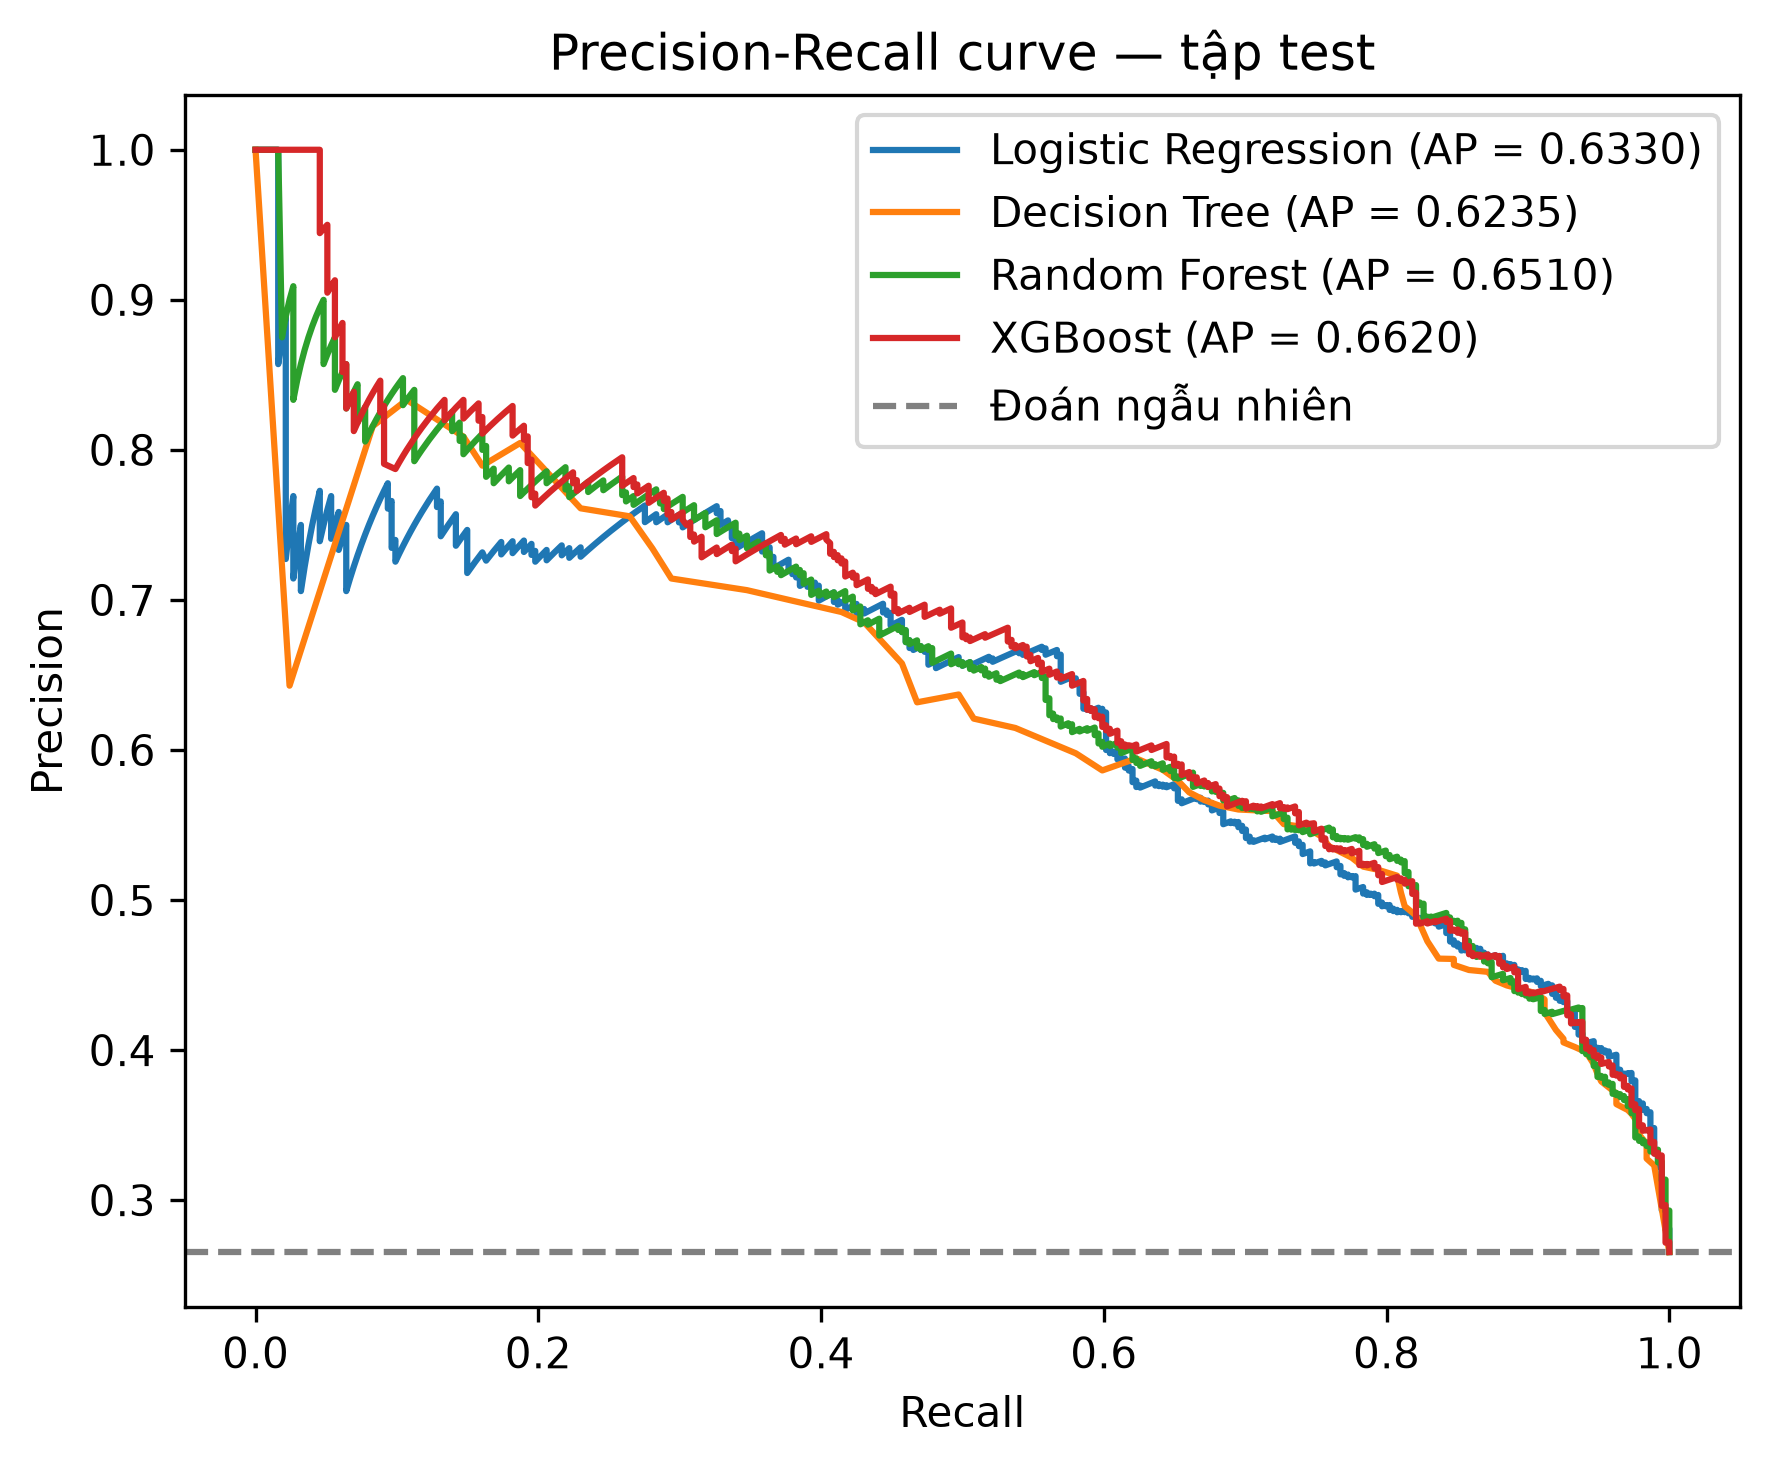

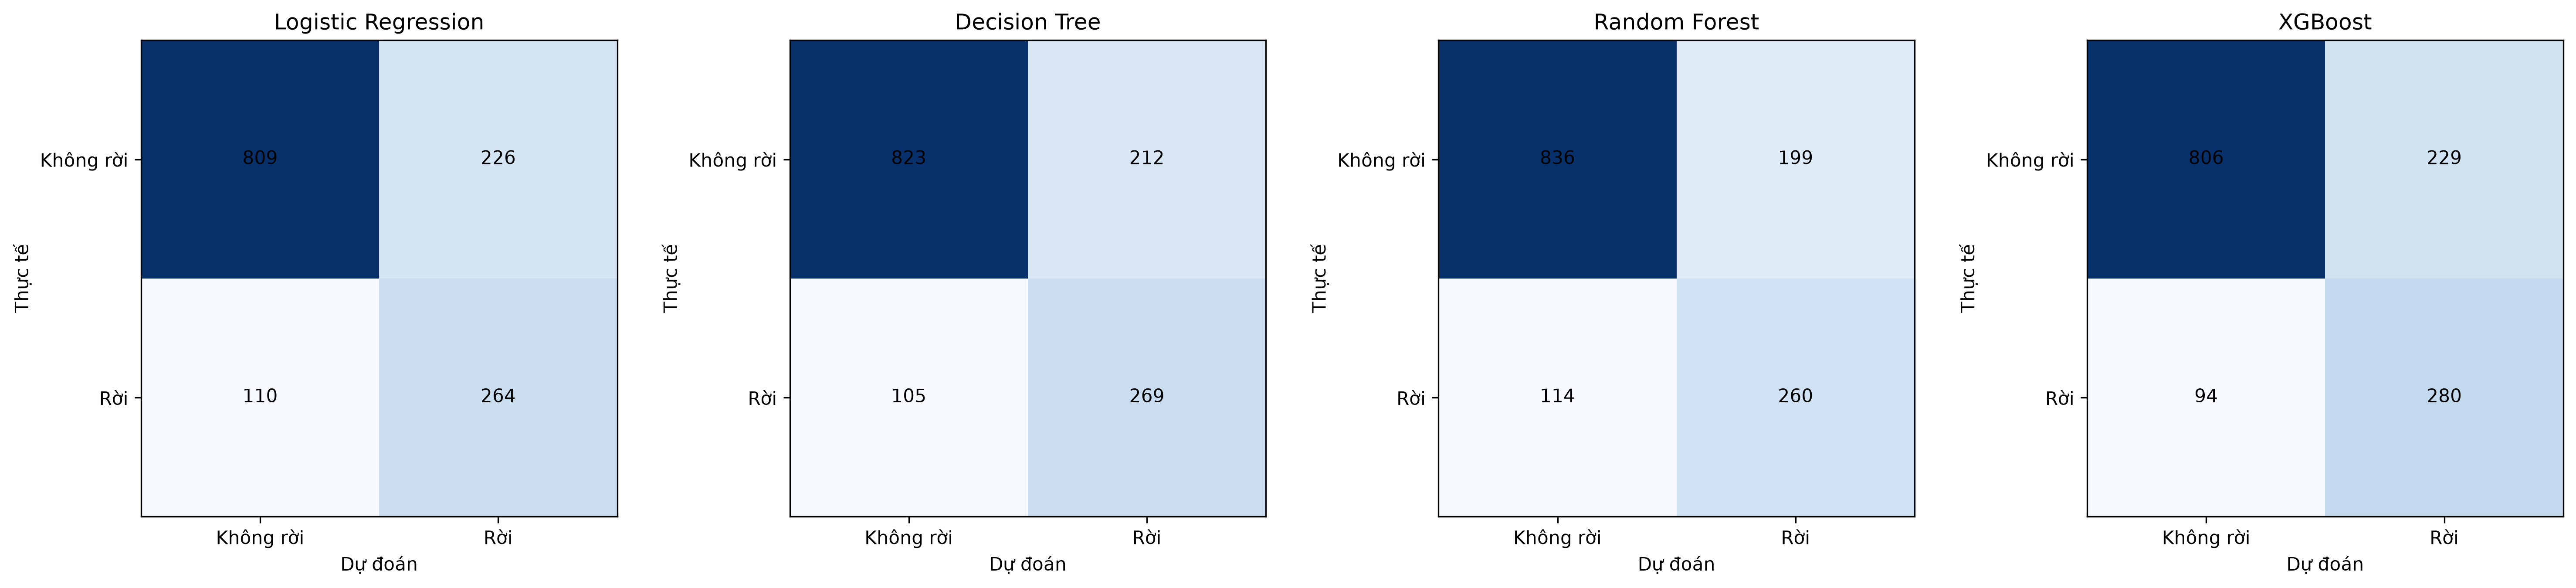

In [12]:
FIG = OUTPUTS / "evaluation/tuned_f1/figures"
display(Image(filename=FIG / "pr_curves.png", width=520))
display(Image(filename=FIG / "confusion_matrices.png", width=950))

### So với lần đánh giá test đầu tiên

Lần đánh giá đầu (29/10) dùng Decision Tree và Random Forest với tham số mặc định,
không xử lý mất cân bằng, ngưỡng 0,5.

In [13]:
first = pd.read_csv(OUTPUTS / "evaluation/test_20261029_190627_230419/test_metrics.csv").set_index("model")
display(pd.DataFrame({
    "F1 ban đầu": first["test_f1"],
    "F1 cuối": test_f1.loc[first.index, "test_f1"],
    "Recall ban đầu": first["test_recall"],
    "Recall cuối": test_f1.loc[first.index, "test_recall"],
    "ROC-AUC ban đầu": first["test_roc_auc"],
    "ROC-AUC cuối": test_f1.loc[first.index, "test_roc_auc"],
}).rename(index=MODEL_LABELS))

,F1 ban đầu,F1 cuối,Recall ban đầu,Recall cuối,ROC-AUC ban đầu,ROC-AUC cuối
model,,,,,,
Decision Tree,0.4921,0.6292,0.4973,0.7193,0.6537,0.8347
Random Forest,0.5438,0.6242,0.4813,0.6952,0.8213,0.8431


## 7. Giải thích mô hình

### 7.1 Permutation importance (XGBoost và Logistic Regression)

Xáo trộn ngẫu nhiên từng đặc trưng gốc trên tập test và đo PR-AUC giảm bao nhiêu.
Giảm càng nhiều thì mô hình càng dựa vào đặc trưng đó. Cách này dùng được cho mọi mô hình
và làm việc trên 19 đặc trưng gốc (không phải các cột one-hot), nên dễ đọc.

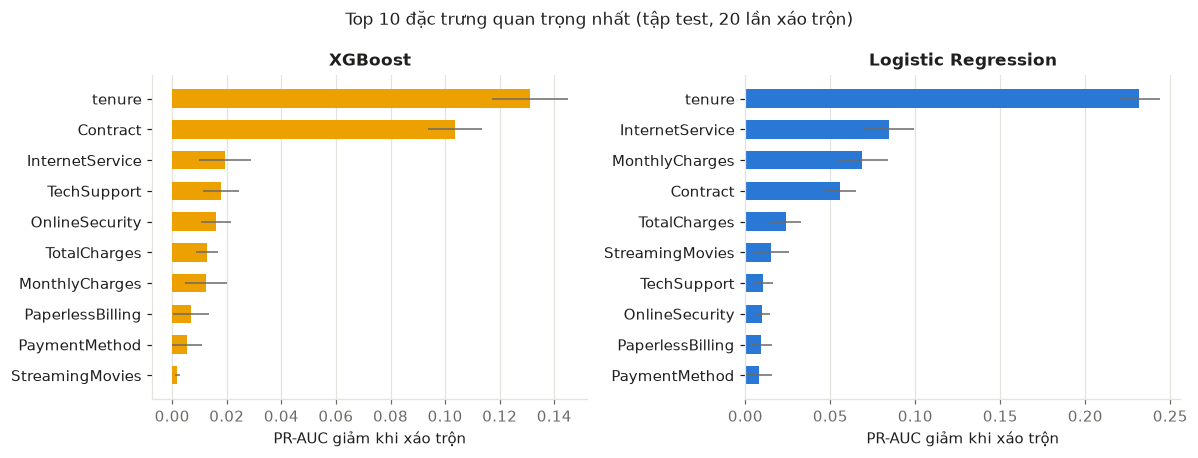

,XGBoost,Logistic Regression
tenure,0.1310,0.2318
Contract,0.1036,0.0556
InternetService,0.0194,0.0844
TechSupport,0.0178,0.0103
OnlineSecurity,0.0162,0.0100
TotalCharges,0.0128,0.0238
MonthlyCharges,0.0124,0.0689
PaperlessBilling,0.0069,0.0090
PaymentMethod,0.0054,0.0081
StreamingMovies,0.0019,0.0151


In [14]:
from sklearn.inspection import permutation_importance

_, X_test, _, y_test = load_train_test()
pipelines = {m: joblib.load(OUTPUTS / f"models/tuned/{m}.joblib") for m in MODELS}

importances = {}
for m in ["xgboost", "logistic_regression"]:
    r = permutation_importance(
        pipelines[m], X_test, y_test, scoring="average_precision",
        n_repeats=20, random_state=42, n_jobs=-1,
    )
    importances[m] = pd.DataFrame(
        {"mean": r.importances_mean, "std": r.importances_std}, index=X_test.columns
    ).sort_values("mean", ascending=False)

TOP = 10
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, m in zip(axes, importances):
    imp = importances[m].head(TOP).iloc[::-1]
    ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=MODEL_COLORS[m],
            height=0.6, error_kw={"ecolor": MUTED, "elinewidth": 1})
    ax.set_title(MODEL_LABELS[m])
    ax.set_xlabel("PR-AUC giảm khi xáo trộn")
    ax.tick_params(axis="y", colors=INK)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Top {TOP} đặc trưng quan trọng nhất (tập test, 20 lần xáo trộn)", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

display(pd.concat({MODEL_LABELS[m]: v["mean"] for m, v in importances.items()}, axis=1)
        .sort_values("XGBoost", ascending=False).head(TOP))

### 7.2 Hệ số Logistic Regression

Hệ số dương làm tăng khả năng rời bỏ, âm làm giảm. `odds_ratio = exp(hệ số)`: ví dụ
1,5 nghĩa là odds rời bỏ tăng 50% khi đặc trưng tăng 1 đơn vị (biến số đã được chuẩn hóa,
nên 1 đơn vị = 1 độ lệch chuẩn) hoặc khi khách hàng thuộc nhóm đó (biến one-hot).

In [15]:
lr = pipelines["logistic_regression"]
coef = pd.DataFrame({
    "feature": lr.named_steps["preprocessor"].get_feature_names_out(),
    "coef": lr.named_steps["model"].coef_[0],
})
coef["feature"] = coef["feature"].str.replace(r"^(numeric|binary|categorical)__", "", regex=True)
coef["odds_ratio"] = np.exp(coef["coef"])

print("Làm tăng khả năng rời bỏ nhiều nhất:")
display(coef.nlargest(8, "coef").set_index("feature"))
print("Làm giảm khả năng rời bỏ nhiều nhất:")
display(coef.nsmallest(8, "coef").set_index("feature"))

Làm tăng khả năng rời bỏ nhiều nhất:


,coef,odds_ratio
feature,,
InternetService_Fiber optic,0.6855,1.9848
Contract_Month-to-month,0.6563,1.9277
TotalCharges,0.4835,1.6217
StreamingMovies_Yes,0.2645,1.3028
StreamingTV_Yes,0.2513,1.2856
PaymentMethod_Electronic check,0.2397,1.2709
OnlineSecurity_No,0.1992,1.2204
TechSupport_No,0.1650,1.1794


Làm giảm khả năng rời bỏ nhiều nhất:


,coef,odds_ratio
feature,,
tenure,-1.1509,0.3163
Contract_Two year,-0.7736,0.4614
MonthlyCharges,-0.6323,0.5314
InternetService_DSL,-0.6085,0.5442
InternetService_No,-0.2676,0.7652
OnlineSecurity_No internet service,-0.2676,0.7652
OnlineBackup_No internet service,-0.2676,0.7652
DeviceProtection_No internet service,-0.2676,0.7652


## 8. Kết luận

### Kết quả chính

- **Mô hình cuối cùng: XGBoost đã tune, `class_weight`, ngưỡng 0,57.** Mô hình được chọn
  trước khi xem tập test, dựa trên PR-AUC cross-validation cao nhất (0,671).
- **Trên tập test:** F1 0,634, recall 0,749, precision 0,550, ROC-AUC 0,846, PR-AUC 0,662.
  Trong 374 khách hàng thực sự rời bỏ, mô hình phát hiện được 280 người; đổi lại có 229
  trên 1.035 khách hàng ở lại bị cảnh báo nhầm.
- **Kết quả test khớp với cross-validation** (PR-AUC 0,671 → 0,662, ROC-AUC 0,850 → 0,846),
  nên quy trình chọn mô hình không bị overfit vào các fold.
- **Logistic Regression gần ngang bằng** (F1 test 0,611, ROC-AUC 0,842) và dễ giải thích hơn.
  Với 374 khách rời trong tập test, chênh lệch F1 cỡ 0,02 giữa các mô hình có thể chỉ là nhiễu.

### Điều gì thực sự giúp ích

| Thay đổi | Tác động | Ghi chú |
|---|---|---|
| Xử lý mất cân bằng bằng `class_weight` | **Lớn** | F1 tăng khoảng +0,04–0,05 với LR, RF, XGBoost; recall tăng khoảng +0,16–0,26 |
| SMOTE | Tốt với LR, yếu hơn với mô hình cây | `class_weight` đơn giản hơn, không sinh dữ liệu giả, hiệu quả tương đương hoặc tốt hơn |
| Tuning siêu tham số | **Lớn với mô hình cây** | Decision Tree: F1 +0,12, PR-AUC +0,24; Random Forest: F1 +0,03, PR-AUC +0,06; chủ yếu nhờ giới hạn độ sâu và kích thước lá, giảm overfit |
| Feature engineering | **Không đáng kể** | Mọi chênh lệch nằm trong khoảng ±0,01, nhỏ hơn độ dao động giữa các fold |
| Chọn ngưỡng | Nhỏ với F1 | Tăng F1 khoảng +0,008 trên CV; trên test lúc tăng lúc giảm. Ngưỡng chủ yếu điều chỉnh cân bằng precision – recall |

- Feature engineering không giúp vì các đặc trưng mới (nhóm tenure, hợp đồng × tenure,
  số dịch vụ…) đều được dựng từ thông tin mà mô hình đã có; mô hình cây tự học được các
  tương tác này, còn Logistic Regression đã nắm được xu hướng chính.
- Cái giá của `class_weight` là precision giảm (Logistic Regression: 0,65 → 0,52): mô hình chấp nhận cảnh báo nhầm
  nhiều hơn để bắt được nhiều khách rời hơn — phù hợp với mục tiêu giữ chân khách hàng.

### Đặc trưng ảnh hưởng đến churn

Cả hai cách giải thích (permutation importance trên test và hệ số Logistic Regression)
đều thống nhất với các nhận định từ EDA:

- **`tenure` quan trọng nhất**: khách hàng càng gắn bó lâu càng ít rời.
- **`Contract`**: hợp đồng theo tháng làm tăng mạnh nguy cơ rời bỏ; hợp đồng 2 năm làm giảm mạnh.
- **`InternetService`**: khách dùng Fiber optic có nguy cơ rời cao hơn, DSL thấp hơn.
- **Dịch vụ hỗ trợ** (`TechSupport`, `OnlineSecurity`): khách không dùng có nguy cơ rời cao hơn.
- **`PaymentMethod` = Electronic check** làm tăng nguy cơ rời.

Lưu ý khi đọc hệ số Logistic Regression: `TotalCharges` gần bằng `tenure × MonthlyCharges`,
nên ba biến này tương quan mạnh với nhau. Dấu hệ số của từng biến riêng lẻ (ví dụ
`MonthlyCharges` âm, `TotalCharges` dương) không nên diễn giải tách rời; permutation importance
đáng tin cậy hơn để đánh giá mức độ quan trọng.

### Hạn chế và hướng phát triển

- Điểm sau tuning hơi lạc quan vì tham số được chọn trên chính các fold dùng để chấm điểm;
  tập test xác nhận mức lạc quan này nhỏ.
- Ngưỡng được chọn theo F1 vì không có dữ liệu chi phí thực tế. Nếu doanh nghiệp coi việc
  bỏ sót khách rời đắt hơn nhiều so với một ưu đãi gửi nhầm, ngưỡng F2 (XGBoost 0,37) cho
  recall 0,88 với precision 0,46.
- Có thể thử thêm: hiệu chỉnh xác suất (calibration), mô hình giải thích theo từng khách
  hàng (SHAP), hoặc chọn ngưỡng theo hàm chi phí khi có số liệu kinh doanh.